# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv('data/creditcard.csv') 

print('Shape:', df.shape)
display(df.head())
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows count:', df.duplicated().sum())

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Duplicate rows count: 1081


## Shapiro-walik test

In [3]:
from scipy.stats import shapiro

# Shapiro–Wilk normality test on the 'Amount' column
stat, p = shapiro(df['Amount'])

print("Shapiro-Wilk Test Statistic:", stat)
print("p-value:", p)

if p > 0.05:
    print("Feature is likely normally distributed (Fail to reject H0)")
else:
    print("Feature is NOT normally distributed (Reject H0)")


Shapiro-Wilk Test Statistic: 0.31004461476982703
p-value: 6.536480219597055e-199
Feature is NOT normally distributed (Reject H0)


/workspaces/Fraud-Detection-Machine-Learning-Model/.venv/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 284807.
  res = hypotest_fun_out(*samples, **kwds)


In [4]:
from scipy.stats import shapiro

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    stat, p = shapiro(df[col])
    print(f"{col}: stat={stat:.4f}, p-value={p:.4f}")


Time: stat=0.9400, p-value=0.0000
V1: stat=0.7990, p-value=0.0000
V2: stat=0.7397, p-value=0.0000
V3: stat=0.9076, p-value=0.0000
V4: stat=0.9692, p-value=0.0000
V5: stat=0.8249, p-value=0.0000
V6: stat=0.8449, p-value=0.0000
V7: stat=0.7247, p-value=0.0000
V8: stat=0.4992, p-value=0.0000
V9: stat=0.9693, p-value=0.0000
V10: stat=0.8144, p-value=0.0000
V11: stat=0.9855, p-value=0.0000
V12: stat=0.8828, p-value=0.0000
V13: stat=0.9990, p-value=0.0000
V14: stat=0.8843, p-value=0.0000
V15: stat=0.9936, p-value=0.0000
V16: stat=0.9503, p-value=0.0000
V17: stat=0.7909, p-value=0.0000
V18: stat=0.9846, p-value=0.0000
V19: stat=0.9830, p-value=0.0000
V20: stat=0.5295, p-value=0.0000
V21: stat=0.4856, p-value=0.0000
V22: stat=0.9830, p-value=0.0000
V23: stat=0.4672, p-value=0.0000
V24: stat=0.9708, p-value=0.0000


/workspaces/Fraud-Detection-Machine-Learning-Model/.venv/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 284807.
  res = hypotest_fun_out(*samples, **kwds)


V25: stat=0.9749, p-value=0.0000
V26: stat=0.9786, p-value=0.0000
V27: stat=0.5784, p-value=0.0000
V28: stat=0.4385, p-value=0.0000
Amount: stat=0.3100, p-value=0.0000
Class: stat=0.0179, p-value=0.0000


## Mutual Information (MI) Analysis Test

In [5]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

# X = all PCA components + Amount
# y = Class
X = df.drop('Class', axis=1)
y = df['Class']

mi_scores = mutual_info_classif(X, y, random_state=42)

mi_results = pd.DataFrame({
    'Feature': X.columns,
    'Mutual Information Score': mi_scores
}).sort_values(by='Mutual Information Score', ascending=False)

print(mi_results)

   Feature  Mutual Information Score
17     V17                  0.008258
14     V14                  0.008136
12     V12                  0.007601
10     V10                  0.007530
11     V11                  0.006831
16     V16                  0.006144
4       V4                  0.004976
3       V3                  0.004952
18     V18                  0.004317
9       V9                  0.004277
7       V7                  0.003951
2       V2                  0.003228
21     V21                  0.002452
27     V27                  0.002444
5       V5                  0.002389
6       V6                  0.002388
1       V1                  0.002127
0     Time                  0.001934
8       V8                  0.001898
28     V28                  0.001871
19     V19                  0.001472
29  Amount                  0.001433
20     V20                  0.001207
23     V23                  0.000762
24     V24                  0.000642
26     V26                  0.000500
2

## Spearman Rank Correlation (Non-linear Relationships)

In [6]:
import pandas as pd

# Compute Spearman correlation with the target class
spearman_corr = df.corr(method='spearman')['Class'].sort_values(ascending=False)

print(spearman_corr)

Class     1.000000
V4        0.063045
V11       0.060143
V2        0.051062
V21       0.035442
V27       0.028311
V8        0.022706
V19       0.022546
V20       0.021574
V28       0.020417
V26       0.005466
V25       0.004682
V22       0.002083
V15      -0.002841
V13      -0.003653
V23      -0.005017
Amount   -0.008339
V24      -0.009188
Time     -0.011692
V5       -0.030147
V18      -0.034872
V6       -0.038410
V1       -0.042424
V17      -0.044335
V7       -0.048308
V9       -0.049499
V16      -0.049936
V3       -0.059278
V10      -0.059564
V12      -0.062870
V14      -0.064613
Name: Class, dtype: float64


## Mann–Whitney U Test (Fraud vs Non-fraud Distribution Differences)

In [7]:
from scipy.stats import mannwhitneyu

fraud = df[df['Class'] == 1]
nonfraud = df[df['Class'] == 0]

for col in df.columns:
    if col != 'Class':
        stat, p = mannwhitneyu(fraud[col], nonfraud[col], alternative='two-sided')
        print(f"{col}: U-stat={stat:.4f}, p-value={p:.4e}")


Time: U-stat=58572378.0000, p-value=4.3862e-10
V1: U-stat=28689110.0000, p-value=1.7408e-113
V2: U-stat=119593684.0000, p-value=1.6504e-163
V3: U-stat=12299525.0000, p-value=1.2110e-219
V4: U-stat=131246382.0000, p-value=3.6259e-248
V5: U-stat=40626254.0000, p-value=3.0537e-58
V6: U-stat=32591968.0000, p-value=2.2310e-93
V7: U-stat=22967158.0000, p-value=1.4642e-146
V8: U-stat=92020960.0000, p-value=8.5099e-34
V9: U-stat=21809136.0000, p-value=8.9437e-154
V10: U-stat=12021914.0000, p-value=9.6111e-222
V11: U-stat=128424209.0000, p-value=4.9106e-226
V12: U-stat=8806982.0000, p-value=8.4160e-247
V13: U-stat=66389021.0000, p-value=5.1215e-02
V14: U-stat=7111691.0000, p-value=1.4716e-260
V15: U-stat=67179133.0000, p-value=1.2951e-01
V16: U-stat=21383707.0000, p-value=1.8082e-156
V17: U-stat=26830255.0000, p-value=9.2194e-124
V18: U-stat=36031912.0000, p-value=2.6490e-77
V19: U-stat=91865436.0000, p-value=2.4020e-33
V20: U-stat=90920024.0000, p-value=1.1281e-30
V21: U-stat=104405154.0000, p

## Data Visualisation

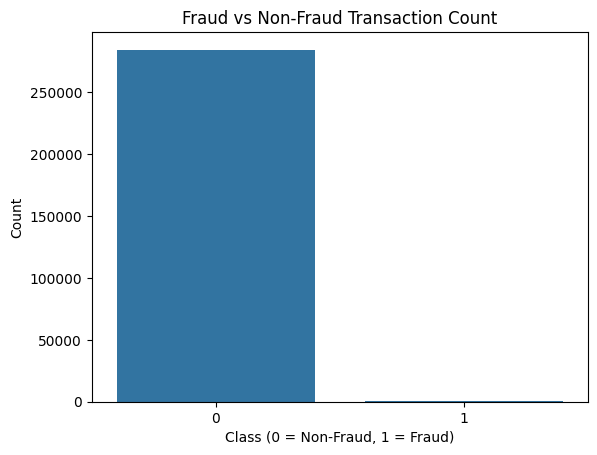

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Class', data=df)
plt.title("Fraud vs Non-Fraud Transaction Count")
plt.xlabel("Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Count")
plt.show()

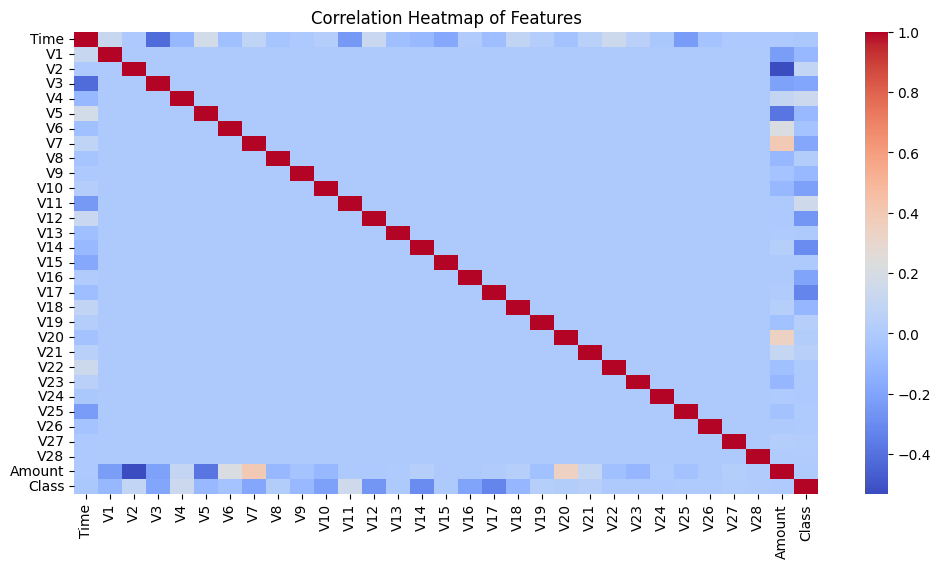

In [9]:
plt.figure(figsize=(12,6))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap of Features")
plt.show()

In [10]:
# Assuming your dataframe name is df
# And fraud labels are in column 'Class'
# And amount column is 'amount'

non_fraud = df[df['Class'] == 0]['Amount']
fraud = df[df['Class'] == 1]['Amount']
percentiles = np.linspace(0, 1, 11)

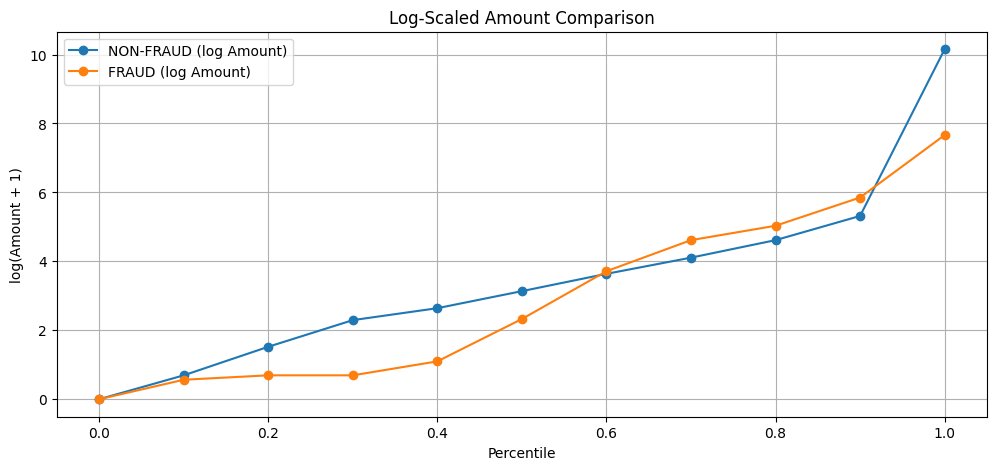

In [11]:
fraud_log = np.log1p(fraud)
nonfraud_log = np.log1p(non_fraud)

fraud_p = np.quantile(fraud_log, percentiles)
nonfraud_p = np.quantile(nonfraud_log, percentiles)

plt.figure(figsize=(12,5))
plt.plot(percentiles, nonfraud_p, marker='o', label="NON-FRAUD (log Amount)")
plt.plot(percentiles, fraud_p, marker='o', label="FRAUD (log Amount)")
plt.title("Log-Scaled Amount Comparison")
plt.xlabel("Percentile")
plt.ylabel("log(Amount + 1)")
plt.grid(True)
plt.legend()
plt.show()


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Split dataset into fraud and non-fraud
non_fraud = df[df['Class'] == 0]['Amount']
fraud = df[df['Class'] == 1]['Amount']

# 2. Define labels for stats
stats_labels = ['Count','Mean','Std','Min','25%','50%','75%','Max']

# 3. Create the non-fraud statistics
non_fraud_stats = np.array([
    non_fraud.count(),
    non_fraud.mean(),
    non_fraud.std(),
    non_fraud.min(),
    non_fraud.quantile(0.25),
    non_fraud.quantile(0.50),
    non_fraud.quantile(0.75),
    non_fraud.max()
])

# 4. Create the fraud statistics
fraud_stats = np.array([
    fraud.count(),
    fraud.mean(),
    fraud.std(),
    fraud.min(),
    fraud.quantile(0.25),
    fraud.quantile(0.50),
    fraud.quantile(0.75),
    fraud.max()
])


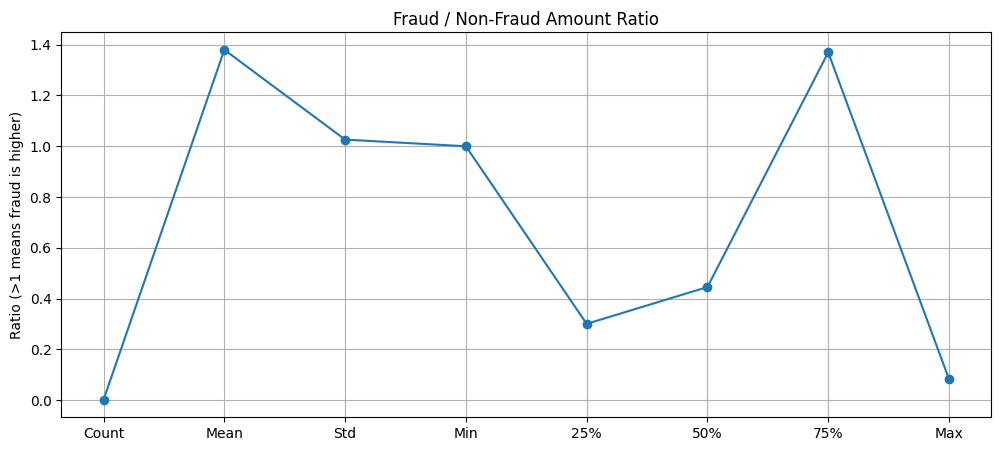

In [13]:
ratio = (fraud_stats + 1) / (non_fraud_stats + 1)

plt.figure(figsize=(12,5))
plt.plot(stats_labels, ratio, marker='o')
plt.title("Fraud / Non-Fraud Amount Ratio")
plt.ylabel("Ratio (>1 means fraud is higher)")
plt.grid(True)
plt.show()


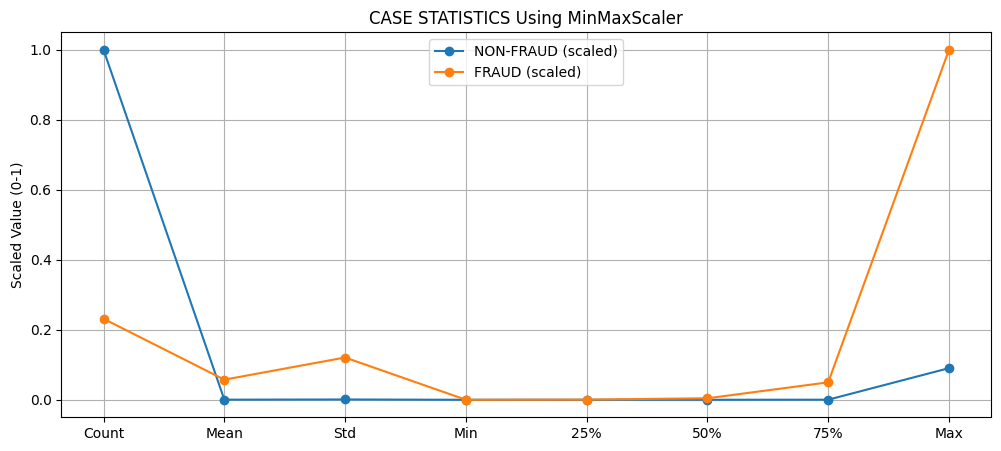

In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
combined = np.vstack([non_fraud_stats, fraud_stats]).T
scaled = scaler.fit_transform(combined)

plt.figure(figsize=(12,5))
plt.plot(stats_labels, scaled[:,0], marker='o', label="NON-FRAUD (scaled)")
plt.plot(stats_labels, scaled[:,1], marker='o', label="FRAUD (scaled)")
plt.title("CASE STATISTICS Using MinMaxScaler")
plt.ylabel("Scaled Value (0-1)")
plt.grid(True)
plt.legend()
plt.show()


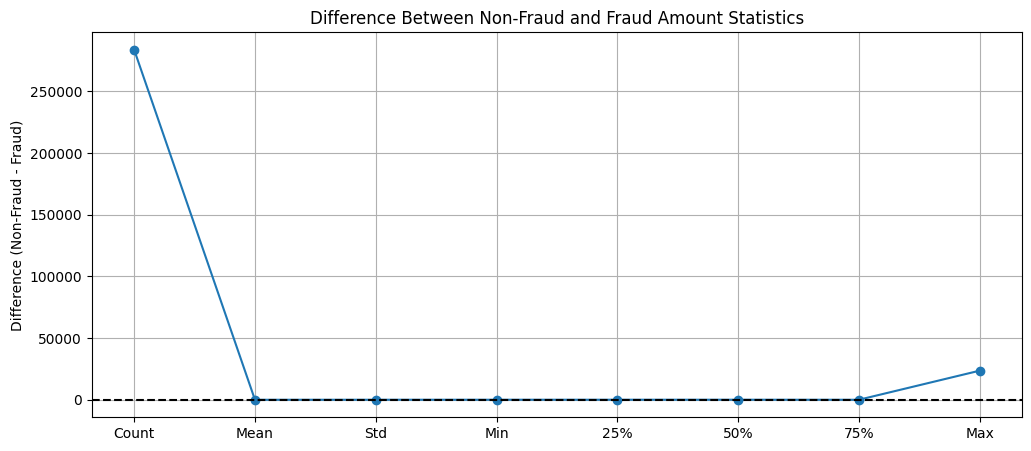

In [15]:
diff = non_fraud_stats - fraud_stats

plt.figure(figsize=(12,5))
plt.plot(stats_labels, diff, marker='o')
plt.axhline(0, color='black', linestyle='--')
plt.title("Difference Between Non-Fraud and Fraud Amount Statistics")
plt.ylabel("Difference (Non-Fraud - Fraud)")
plt.grid(True)
plt.show()


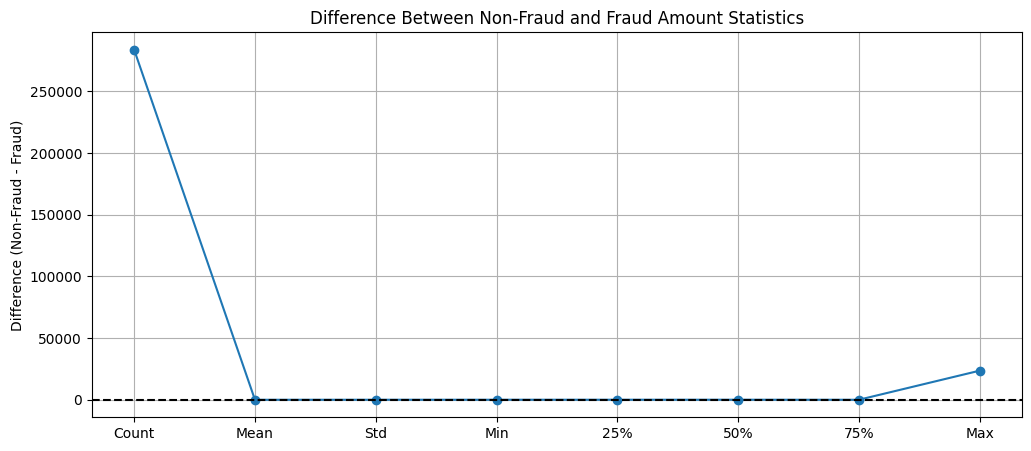

In [16]:
diff = non_fraud_stats - fraud_stats

plt.figure(figsize=(12,5))
plt.plot(stats_labels, diff, marker='o')
plt.axhline(0, color='black', linestyle='--')
plt.title("Difference Between Non-Fraud and Fraud Amount Statistics")
plt.ylabel("Difference (Non-Fraud - Fraud)")
plt.grid(True)
plt.show()


## Tests

### T-TEST 

In [17]:
from scipy.stats import ttest_ind
import numpy as np

t_results = {}

group_0 = df[df['Class'] == 0]
group_1 = df[df['Class'] == 1]

print("T-Test Results:\n")

for col in df.select_dtypes(include=['int64', 'float64']).columns:
    if col == 'Class':
        continue

    # Ensure both groups have variance
    if group_0[col].nunique() > 1 and group_1[col].nunique() > 1:
        stat, p_val = ttest_ind(group_0[col], group_1[col], equal_var=False)
        t_results[col] = p_val
        print(f"{col}: p-value = {p_val}")
    else:
        print(f"{col}: skipped (not enough variance)\n")

# Sort by significance
sorted_t = dict(sorted(t_results.items(), key=lambda x: x[1]))

print("\n\nFeatures Ranked by Significance (lower p-value = more important):")
for col, p_val in sorted_t.items():
    print(f"{col}: {p_val}")


T-Test Results:

Time: p-value = 1.654563949048748e-10
V1: p-value = 5.4916429825378706e-45
V2: p-value = 1.28857976120953e-59
V3: p-value = 4.786081407428208e-75
V4: p-value = 4.587316921388204e-136
V5: p-value = 1.4970277071054125e-33
V6: p-value = 5.880377860840106e-50
V7: p-value = 4.292231319441221e-52
V8: p-value = 0.06275811803424985
V9: p-value = 1.1935046623364428e-79
V10: p-value = 3.3828836506135362e-93
V11: p-value = 4.577212375356478e-120
V12: p-value = 1.4813165028380868e-112
V13: p-value = 0.02842016819253238
V14: p-value = 1.040150709902639e-140
V15: p-value = 0.049933360772518885
V16: p-value = 7.905325639437722e-84
V17: p-value = 1.5580938057841855e-71
V18: p-value = 2.6392225457941318e-52
V19: p-value = 6.707056605381362e-21
V20: p-value = 1.6876894180533079e-09
V21: p-value = 4.882129855322919e-05
V22: p-value = 0.8346791940015031
V23: p-value = 0.5710402154248271
V24: p-value = 7.565212734686299e-06
V25: p-value = 0.24872292184544406
V26: p-value = 0.01542128272640

### ANOVA Test

In [18]:
import pandas as pd
from scipy.stats import f_oneway

# Separate groups based on target class (0 = non-fraud, 1 = fraud)
group_0 = df[df['Class'] == 0]
group_1 = df[df['Class'] == 1]

anova_results = {}

print("ANOVA Results for Numerical Features:\n")

for col in df.select_dtypes(include=['int64', 'float64']).columns:
    if col == 'Class':
        continue  # skip target variable
    
    # Perform ANOVA only if both groups have valid data
    if group_0[col].nunique() > 1 and group_1[col].nunique() > 1:
        f_stat, p_val = f_oneway(group_0[col], group_1[col])
        anova_results[col] = p_val
        print(f"{col}:  p-value = {p_val}")
    else:
        print(f"{col}: skipped (not enough variance)\n")

# Sort features by significance
sorted_results = dict(sorted(anova_results.items(), key=lambda x: x[1]))

print("\n\nFeatures ranked by significance (lower p-value = more important):")
for feature, p_val in sorted_results.items():
    print(f"{feature}: {p_val}")


ANOVA Results for Numerical Features:

Time:  p-value = 4.818268891796069e-11
V1:  p-value = 0.0
V2:  p-value = 0.0
V3:  p-value = 0.0
V4:  p-value = 0.0
V5:  p-value = 0.0
V6:  p-value = 4.213111345323121e-120
V7:  p-value = 0.0
V8:  p-value = 2.7406731012471565e-26
V9:  p-value = 0.0
V10:  p-value = 0.0
V11:  p-value = 0.0
V12:  p-value = 0.0
V13:  p-value = 0.014737338961005646
V14:  p-value = 0.0
V15:  p-value = 0.024201426001457624
V16:  p-value = 0.0
V17:  p-value = 0.0
V18:  p-value = 0.0
V19:  p-value = 5.8015173021418126e-77
V20:  p-value = 7.964292023532907e-27
V21:  p-value = 3.0022685578496535e-103
V22:  p-value = 0.6673596913925154
V23:  p-value = 0.15186019852142135
V24:  p-value = 0.00011637602808852438
V25:  p-value = 0.07752500938140117
V26:  p-value = 0.017419705371241972
V27:  p-value = 6.4419203436714914e-21
V28:  p-value = 3.595353561989655e-07
Amount:  p-value = 0.0026512206491917135


Features ranked by significance (lower p-value = more important):
V1: 0.0
V2: 0

# Data Preprocessing

## Data Cleaning

In [19]:
# Count duplicate rows
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)
# Remove duplicate rows
df = df.drop_duplicates()

# Verify again
print("After removing duplicates:", df.duplicated().sum())
print("New dataset shape:", df.shape)

Number of duplicate rows: 1081
After removing duplicates: 0
New dataset shape: (283726, 31)


## Scaling

In [20]:
scaler = StandardScaler()
df[['Time','Amount']] = scaler.fit_transform(df[['Time','Amount']])

## Test-Train Split

In [21]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## SMOTE

In [22]:
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print("Data ready. After SMOTE:", X_train_res.shape)

Data ready. After SMOTE: (453204, 30)


# Model Training

## Logistic Regression

In [23]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_res, y_train_res)
print("Logistic Regression Trained")

Logistic Regression Trained


## Random Forest

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_res, y_train_res)
print("Random Forest Trained")

Random Forest Trained


## KNN

In [25]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_res, y_train_res)
print("KNN Trained")

KNN Trained


## XGBoost

In [26]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train_res, y_train_res)
print("XGBoost Trained")

XGBoost Trained


## CatBoost

In [27]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.05,
    verbose=0,
    random_state=42
)
cat_model.fit(X_train_res, y_train_res)
print("CatBoost Trained")

CatBoost Trained


# Model Evaluation

## Prediction

In [28]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, solver='liblinear', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        #use_label_encoder=False,
        eval_metric="logloss"
    ),
    "CatBoost": CatBoostClassifier(verbose=0)
}

results = []
roc_data = {}
pr_data = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_res, y_train_res)
print("\nTraining completed!")


for name, model in models.items():
    print(f"Evaluating {name}...")

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1] if hasattr(model,"predict_proba") else model.decision_function(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append([name, acc, prec, rec, f1, auc])

    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

    # PR Curve
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    pr_data[name] = (precision, recall, ap)

results_df = pd.DataFrame(results, columns=["Model","Accuracy","Precision","Recall","F1-Score","AUC"])

Training Logistic Regression...
Training Random Forest...
Training KNN...
Training XGBoost...
Training CatBoost...

Training completed!
Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating KNN...
Evaluating XGBoost...
Evaluating CatBoost...


In [29]:
y_pred = {}
y_prob = {}

for name, model in models.items():
    print(f"\nPredicting with {name}...")

    # 1. Class prediction with default threshold
    y_pred[name] = model.predict(X_test)

    # 2. Probability scores
    # If model provides predict_proba → use it
    # Otherwise → use decision_function
    if hasattr(model, "predict_proba"):
        y_prob[name] = model.predict_proba(X_test)[:, 1]
    else:
        y_prob[name] = model.decision_function(X_test)

print("\nPrediction completed for all models.")



Predicting with Logistic Regression...

Predicting with Random Forest...

Predicting with KNN...

Predicting with XGBoost...

Predicting with CatBoost...

Prediction completed for all models.


## Confusion Matrix & Classification Report

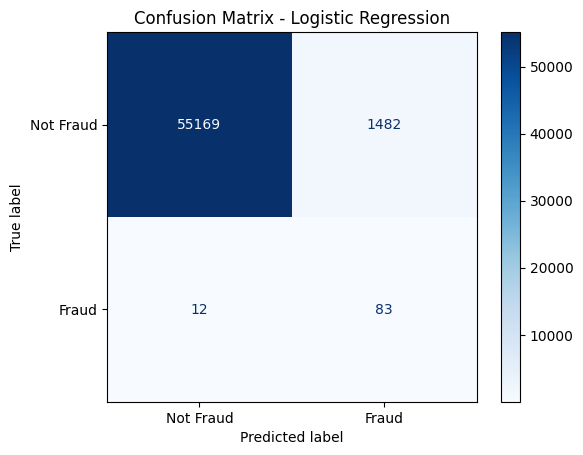

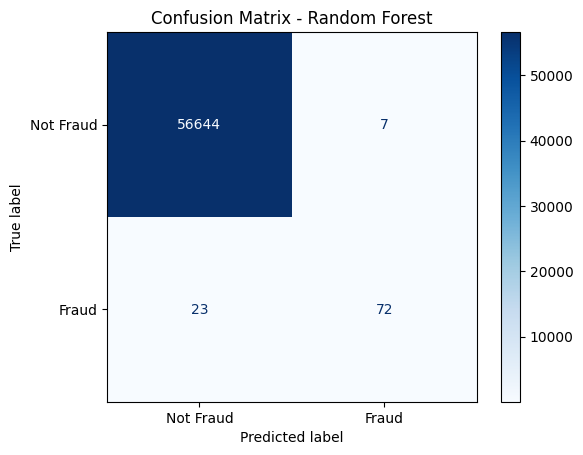

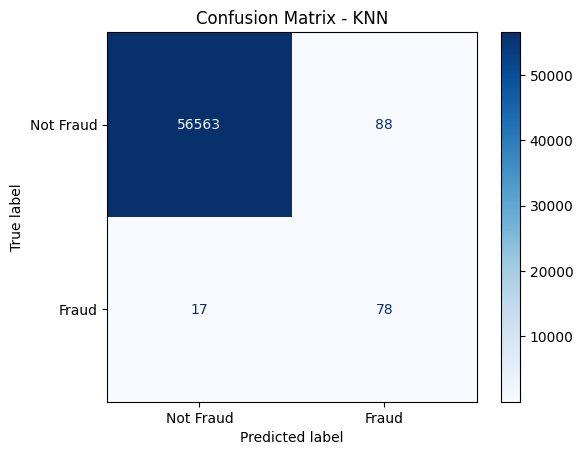

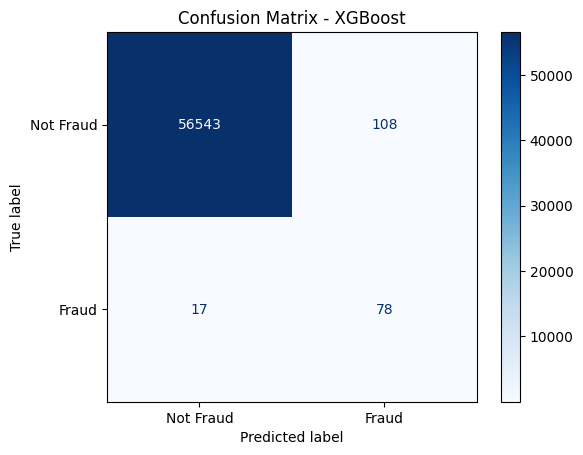

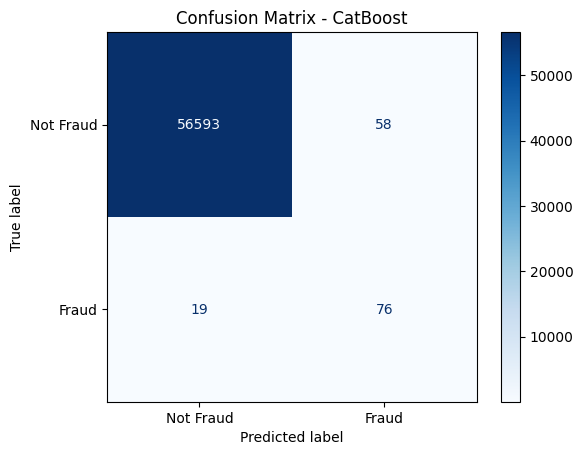

In [30]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Not Fraud", "Fraud"])
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()


## ROC Curve

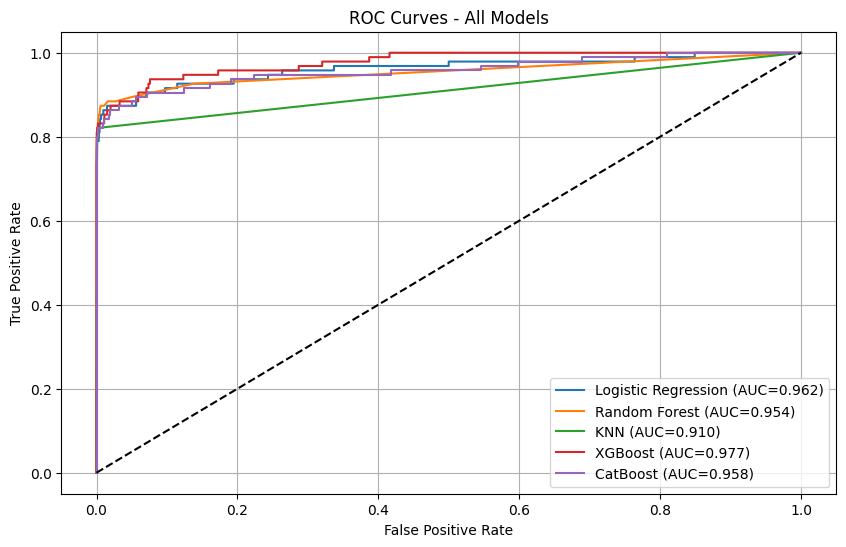

In [31]:
plt.figure(figsize=(10,6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curves - All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

## Precision-Recall (PR) Curve

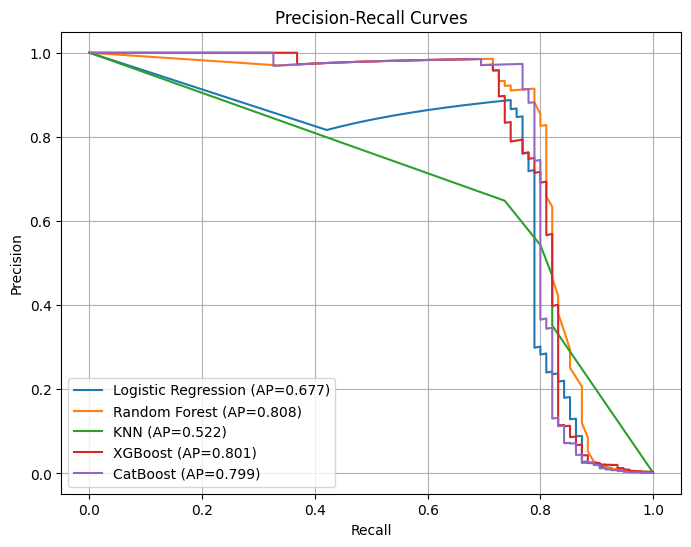

In [32]:
plt.figure(figsize=(8,6))
for name,(prec, rec, ap) in pr_data.items():
    plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.show()

## Optimal Threshold

Best Model: XGBoost
Optimal Threshold for Best F1: 0.9500000000000001


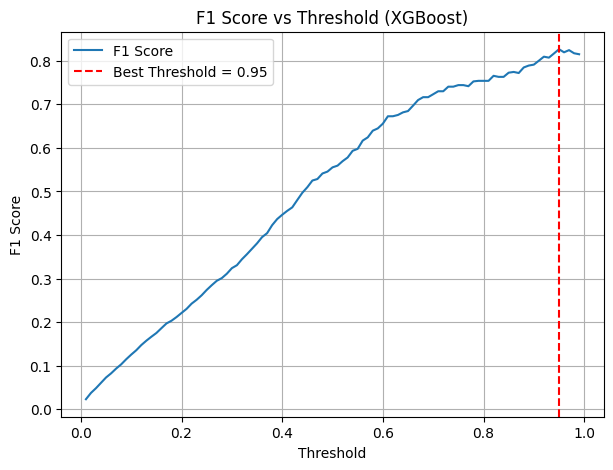

In [33]:
# Best model selection by AUC → then F1
best = results_df.sort_values(by=["AUC","F1-Score"], ascending=False).iloc[0]
best_name = best['Model']
best_model = models[best_name]
print("Best Model:", best_name)

#print(f"Finding optimal threshold for best model: {best_name}...")

# Get probability scores for the best model
if hasattr(best_model, "predict_proba"):
    y_scores = best_model.predict_proba(X_test)[:, 1]
else:
    y_scores = best_model.decision_function(X_test)

# Test thresholds from 0.01 to 0.99
thresholds = np.linspace(0.01, 0.99, 99)
f1_scores = []

for t in thresholds:
    y_pred_t = (y_scores >= t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_t))

# Best threshold
best_t = thresholds[np.argmax(f1_scores)]
print("Optimal Threshold for Best F1:", best_t)

# Plot F1 vs Threshold
plt.figure(figsize=(7,5))
plt.plot(thresholds, f1_scores, label="F1 Score")
plt.axvline(best_t, color='red', linestyle='--', label=f"Best Threshold = {best_t:.2f}")
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title(f"F1 Score vs Threshold ({best_name})")
plt.grid(True)
plt.legend()
plt.show()

## Model Comparision Summary

===== MODEL COMPARISON SUMMARY =====



,Model,Accuracy,Precision,Recall,F1-Score,AUC
3,XGBoost,0.997797,0.419355,0.821053,0.555160,0.977453
0,Logistic Regression,0.973672,0.053035,0.873684,0.100000,0.962025
4,CatBoost,0.998643,0.567164,0.800000,0.663755,0.957515
1,Random Forest,0.999471,0.911392,0.757895,0.827586,0.954320
2,KNN,0.998150,0.469880,0.821053,0.597701,0.909967


/tmp/ipykernel_19670/3617172973.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")


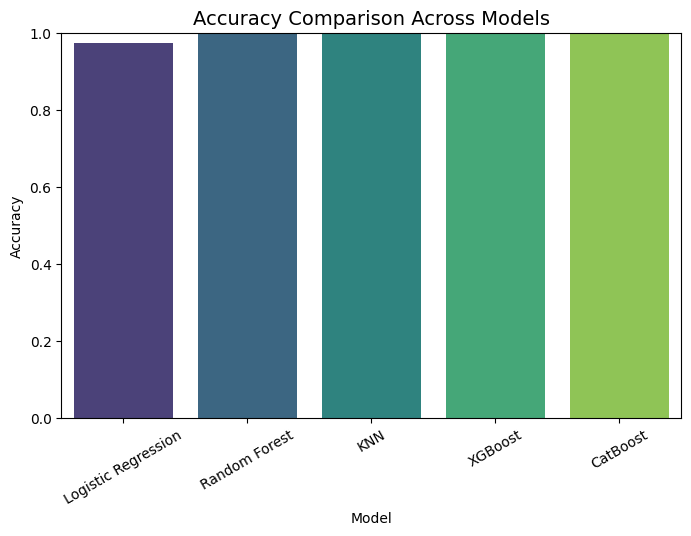

/tmp/ipykernel_19670/3617172973.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")


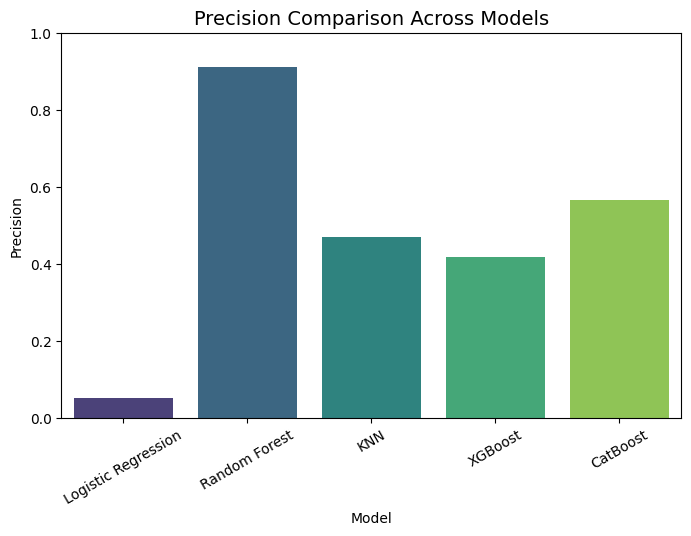

/tmp/ipykernel_19670/3617172973.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")


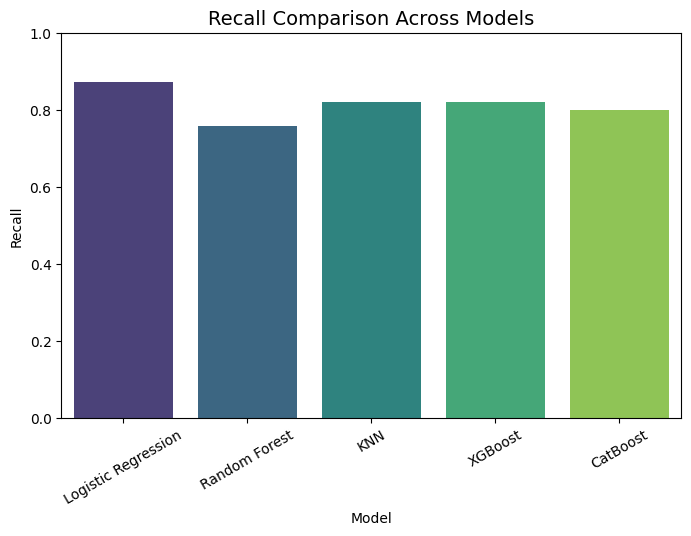

/tmp/ipykernel_19670/3617172973.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")


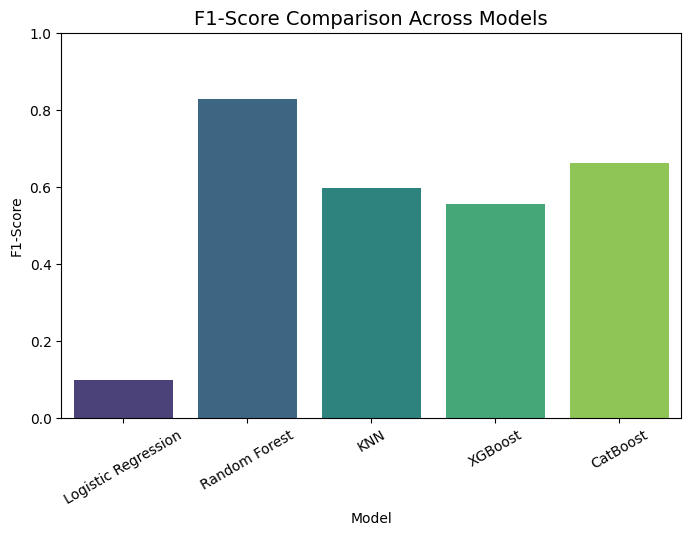

/tmp/ipykernel_19670/3617172973.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")


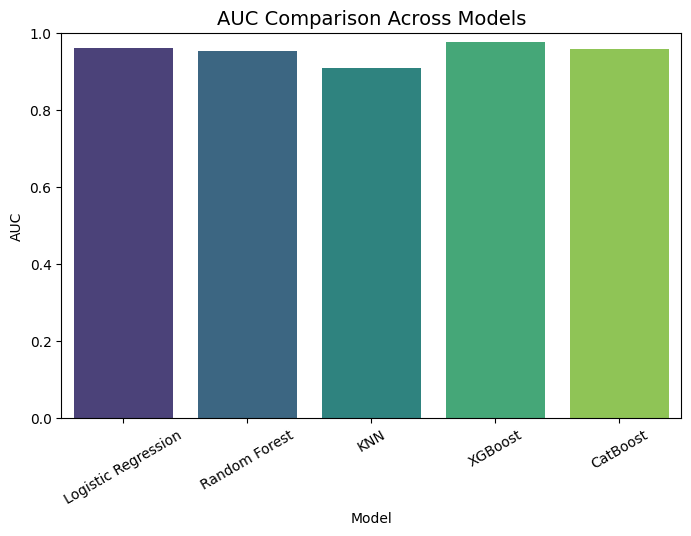

In [34]:
print("===== MODEL COMPARISON SUMMARY =====\n")
display(results_df.sort_values(by=["AUC","F1-Score"], ascending=False))

# Plot comparison
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]

for metric in metrics:
    plt.figure(figsize=(8,5))
    sns.barplot(x="Model", y=metric, data=results_df, palette="viridis")
    plt.title(f"{metric} Comparison Across Models", fontsize=14)
    plt.xticks(rotation=30)
    plt.ylim(0, 1)
    plt.show()


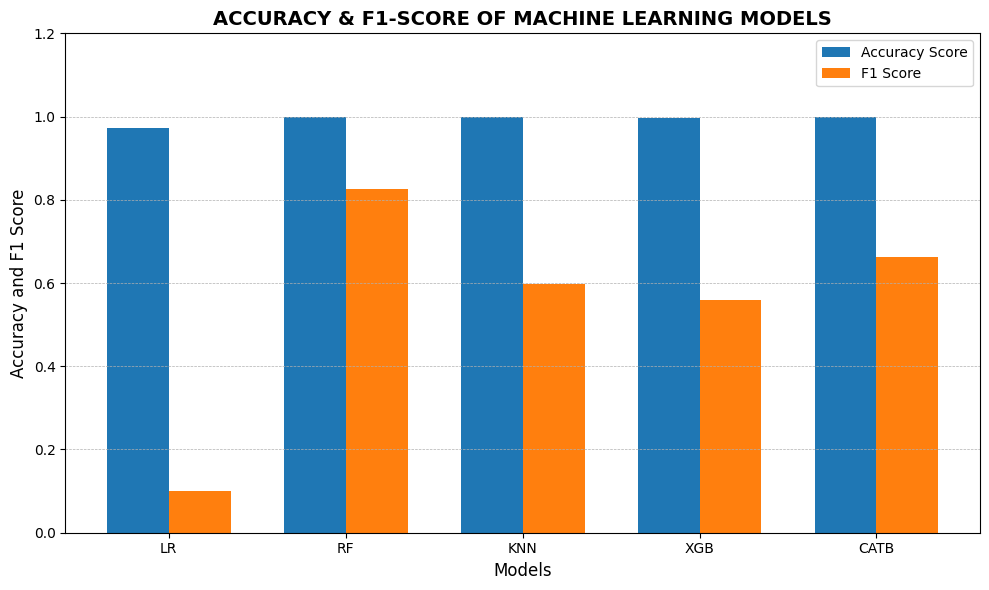

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = ['LR', 'RF', 'KNN', 'XGB', 'CATB']

# Replace these with your actual results
accuracy_scores = [0.973, 0.999, 0.998, 0.997, 0.998]       # Example values
f1_scores =       [0.100, 0.827, 0.597, 0.559, 0.663]       # Example values

x = np.arange(len(models))
width = 0.35  # bar width

plt.figure(figsize=(10, 6))

# Bars
plt.bar(x - width/2, accuracy_scores, width, label='Accuracy Score')
plt.bar(x + width/2, f1_scores, width, label='F1 Score')

# Labels
plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy and F1 Score', fontsize=12)
plt.title('ACCURACY & F1-SCORE OF MACHINE LEARNING MODELS', fontsize=14, fontweight='bold')
plt.xticks(x, models)
plt.ylim(0, 1.2)

plt.legend()
plt.grid(axis='y', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


Accuracy Scores: [0.9991365030134283, 0.9995065731505305, 0.9994713283755683, 0.9992598597257957, 0.9994889507630493]
F1 Scores: [0.6956521739130435, 0.8313253012048193, 0.8170731707317073, 0.7666666666666667, 0.8242424242424242]


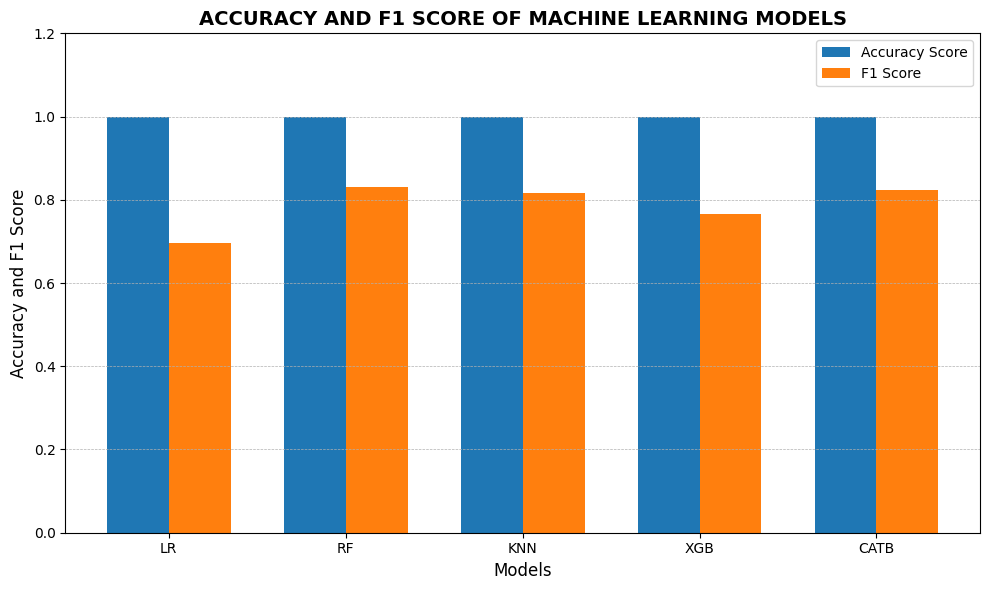

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# -----------------------------
# 1. Train Your Models
# -----------------------------

# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

# XGBoost
import xgboost
xgb = xgboost.XGBClassifier()
xgb.fit(X_train, y_train)

# CatBoost
from catboost import CatBoostClassifier
catb = CatBoostClassifier(verbose=0)
catb.fit(X_train, y_train)

# -----------------------------
# 2. Predict
# -----------------------------

models = {
    "LR": lr,
    "RF": rf,
    "KNN": knn,
    "XGB": xgb,
    "CATB": catb
}

accuracy_scores = []
f1_scores = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    f1_scores.append(f1_score(y_test, y_pred))
    
print("Accuracy Scores:", accuracy_scores)
print("F1 Scores:", f1_scores)

# -----------------------------
# 3. Plot Graph
# -----------------------------

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, accuracy_scores, width, label='Accuracy Score')
plt.bar(x + width/2, f1_scores, width, label='F1 Score')

plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy and F1 Score', fontsize=12)
plt.title('ACCURACY AND F1 SCORE OF MACHINE LEARNING MODELS', fontsize=14, fontweight='bold')
plt.xticks(x, list(models.keys()))
plt.ylim(0, 1.2)
plt.legend()
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()
